# ArboMol Classificator — treinamento do modelo

Notebook de treino **oficial e reprodutível** do classificador multiclasse de moléculas
com potencial atividade contra Dengue, Zika e Chikungunya.

Ele refaz todo o caminho, da planilha bruta ao arquivo `modelo_final.pkl` usado pela
plataforma web, e produz as tabelas e figuras do artigo.

---

## O que mudou em relação ao notebook exploratório

O notebook anterior (`exploracao_modelos.ipynb`) é o registro histórico da exploração.
Duas falhas metodológicas foram corrigidas aqui:

**1. Vazamento de dados.** Lá, o `RobustScaler` e o `SelectKBest` foram ajustados sobre
o conjunto **inteiro** antes da divisão treino/teste. Como o `SelectKBest` usa os rótulos
para escolher os descritores, a seleção enxergou os rótulos do teste, e as métricas
subiram artificialmente para perto de 0,80. Aqui, as quatro etapas ficam dentro de uma
`Pipeline` do `imbalanced-learn` e são reajustadas **dentro de cada partição de treino**.
A seção 3 demonstra a diferença lado a lado.

**2. Falta de reprodutibilidade.** O modelo salvo lá usava `ExtraTreesClassifier()` com os
parâmetros padrão e **sem semente**, então cada execução gerava um modelo diferente. Aqui
todas as etapas estocásticas usam `random_state = 42`, e a seção 8 verifica que dois
treinos produzem um modelo byte a byte idêntico.

In [1]:
import hashlib, os, warnings
from collections import Counter

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors
from rdkit.ML.Descriptors import MoleculeDescriptors

from sklearn.base import clone
from sklearn.preprocessing import LabelEncoder, RobustScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, balanced_accuracy_score)
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                              ExtraTreesClassifier, AdaBoostClassifier)
from sklearn.svm import SVC, LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline

warnings.filterwarnings("ignore")
RDLogger.DisableLog("rdApp.*")

# ----- configuracao -----
RANDOM_STATE = 42      # semente unica, usada em todas as etapas estocasticas
N_FEATURES   = 20      # descritores mantidos pelo SelectKBest
N_ESTIMATORS = 200     # arvores do ExtraTrees
TEST_SIZE    = 0.20
N_SPLITS, N_REPEATS = 5, 5

DATA_DIR = "data" if os.path.isdir("data") else "."
OUT_DIR  = "."

# ----- estilo dos graficos -----
AZUL, LARANJA, VERDE = "#2a78d6", "#eb6834", "#1baf7a"
COR_CLASSE = {"chikungunya": AZUL, "dengue": LARANJA, "zika": VERDE}
TINTA, TINTA2 = "#0b0b0b", "#52514e"

plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 200, "font.size": 10,
    "axes.edgecolor": "#d8d7d2", "axes.labelcolor": TINTA2, "axes.titlecolor": TINTA,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlepad": 12, "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": TINTA2, "ytick.color": TINTA2,
    "xtick.direction": "out", "ytick.direction": "out",
    "grid.color": "#ececea", "grid.linewidth": 0.8,
    "figure.facecolor": "white", "axes.facecolor": "white",
})

print("pandas", pd.__version__, "| numpy", np.__version__)
import sklearn, rdkit
print("scikit-learn", sklearn.__version__, "| rdkit", rdkit.__version__)
print("semente:", RANDOM_STATE, "| dados em:", os.path.abspath(DATA_DIR))

pandas 3.0.5 | numpy 2.2.6
scikit-learn 1.7.2 | rdkit 2026.09.1
semente: 42 | dados em: /home/claude/nb/run/data


---
## 1. Dados brutos

Três coleções de moléculas, uma por vírus. Cada planilha tem `Entry Number` (identificador
na base de origem) e `Smiles` (a estrutura química).

In [2]:
FONTES = [("dengue", "dengue.xlsx"),
          ("zika", "zika_virus.xlsx"),
          ("chikungunya", "chikungunya.xlsx")]

brutos = {rot: pd.read_excel(os.path.join(DATA_DIR, arq)) for rot, arq in FONTES}

for rot, df in brutos.items():
    print(f"{rot:12s} {len(df):4d} linhas   colunas: {list(df.columns)}")

brutos["dengue"].head(3)

dengue        655 linhas   colunas: ['Entry Number', 'Smiles']
zika          245 linhas   colunas: ['Entry Number', 'Smiles']
chikungunya   186 linhas   colunas: ['Entry Number', 'Smiles']


,Entry Number,Smiles
0,90077,CC[C@H](C)C(=O)O[C@H]1C[C@H](C=C2[C@H]1[C@H]([...
1,90670,CC1=C(C(CCC1)(C)C)/C=C/C(=C/C=C/C(=C/C(=O)Nc2c...
2,1075313,CC1(Cc2c(c(c(s2)NC(=O)Cc3ccc(cc3)S(=O)(=O)N)C#...


## 2. Curadoria

Três passos, nesta ordem:

1. **Validação e canonização.** Cada SMILES é interpretado pelo RDKit, sanitizado e
   reescrito na forma canônica. Estruturas que não são interpretadas saem.
2. **Deduplicação dentro da classe**, pelo SMILES canônico.
3. **Deduplicação entre classes.** Uma molécula que aparece em mais de uma coleção é
   atribuída à classe de **menor cardinalidade**. Sem essa prioridade, as classes raras
   seriam esvaziadas pelas moléculas também reportadas para o dengue.

> **Limitação a registrar no artigo.** O passo 3 transforma um problema que é, na
> biologia, multirrótulo (uma molécula pode ter atividade contra mais de um vírus) em um
> problema de rótulo único. Na prática, a classe "dengue" passa a significar
> "dengue e nenhum outro". A célula abaixo quantifica quantas moléculas foram afetadas.

In [3]:
def canonizar(smiles):
    """Valida, sanitiza e canoniza um SMILES. Retorna None se invalido."""
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    try:
        Chem.SanitizeMol(mol)
        return Chem.MolToSmiles(mol)
    except Exception:
        return None


limpos = {}
for rot, df in brutos.items():
    d = df.copy()
    d["smiles_clean"] = d["Smiles"].apply(canonizar)
    invalidos = d["smiles_clean"].isna().sum()
    d = d.dropna(subset=["smiles_clean"])
    duplicatas = d.duplicated(subset=["smiles_clean"]).sum()
    d = d.drop_duplicates(subset=["smiles_clean"])
    limpos[rot] = d
    print(f"{rot:12s} {len(df):4d} -> {len(d):4d}   "
          f"({invalidos} invalidos, {duplicatas} duplicatas internas)")

dengue        655 ->  655   (0 invalidos, 0 duplicatas internas)
zika          245 ->  244   (1 invalidos, 0 duplicatas internas)


chikungunya   186 ->  186   (0 invalidos, 0 duplicatas internas)


In [4]:
# deduplicacao entre classes: classes menores tem prioridade
vistos, final = set(), {}
for rot, d in sorted(limpos.items(), key=lambda kv: len(kv[1])):
    mantidos = d[~d["smiles_clean"].isin(vistos)].copy()
    removidos = len(d) - len(mantidos)
    vistos.update(mantidos["smiles_clean"])
    mantidos["label"] = rot
    final[rot] = mantidos
    print(f"{rot:12s} {len(d):4d} -> {len(mantidos):4d}   ({removidos} ja presentes numa classe menor)")

df_all = pd.concat(final.values(), ignore_index=True)
multivirus = sum(len(limpos[r]) - len(final[r]) for r in final)
print(f"\ntotal apos deduplicacao: {len(df_all)}")
print(f"moleculas presentes em mais de uma colecao: {multivirus} "
      f"({100*multivirus/sum(len(d) for d in limpos.values()):.1f}% do conjunto limpo)")

chikungunya   186 ->  186   (0 ja presentes numa classe menor)
zika          244 ->  242   (2 ja presentes numa classe menor)
dengue        655 ->  487   (168 ja presentes numa classe menor)

total apos deduplicacao: 915
moleculas presentes em mais de uma colecao: 170 (15.7% do conjunto limpo)


## 3. Descritores moleculares

Os 217 descritores 2D do RDKit (`Descriptors._descList`): propriedades físico-químicas,
índices topológicos e eletrotopológicos, contagens de anéis e de fragmentos funcionais.

In [5]:
def calcular_descritores(df):
    nomes = [n for n, _ in Descriptors._descList]
    calc = MoleculeDescriptors.MolecularDescriptorCalculator(nomes)
    linhas = []
    for smi in df["Smiles"]:
        mol = Chem.MolFromSmiles(smi)
        linhas.append(dict(zip(nomes, calc.CalcDescriptors(mol))) if mol else {})
    return pd.concat([df.reset_index(drop=True), pd.DataFrame(linhas)], axis=1)


df_desc = calcular_descritores(df_all)
antes = len(df_desc)
df_desc = df_desc.dropna().reset_index(drop=True)
print(f"removidas por descritor ausente: {antes - len(df_desc)}")

X = df_desc.select_dtypes(include="number").drop(columns=["Entry Number"])
le = LabelEncoder()
y = le.fit_transform(df_desc["label"])

print(f"\nconjunto final: {X.shape[0]} moleculas x {X.shape[1]} descritores")
print("classes:", dict(zip(le.classes_, np.bincount(y).tolist())))

removidas por descritor ausente: 3

conjunto final: 912 moleculas x 217 descritores
classes: {'chikungunya': 186, 'dengue': 486, 'zika': 240}


In [6]:
# ---- Tabela 1: composicao do conjunto em cada etapa ----
tab1 = pd.DataFrame({
    "Bruto":        {r: len(brutos[r]) for r in brutos},
    "Após limpeza": {r: len(final[r]) for r in final},
    "Final":        df_desc["label"].value_counts().to_dict(),
}).loc[["dengue", "zika", "chikungunya"]]
tab1.loc["Total"] = tab1.sum()
display(tab1)

,Bruto,Após limpeza,Final
dengue,655,487,486
zika,245,242,240
chikungunya,186,186,186
Total,1086,915,912


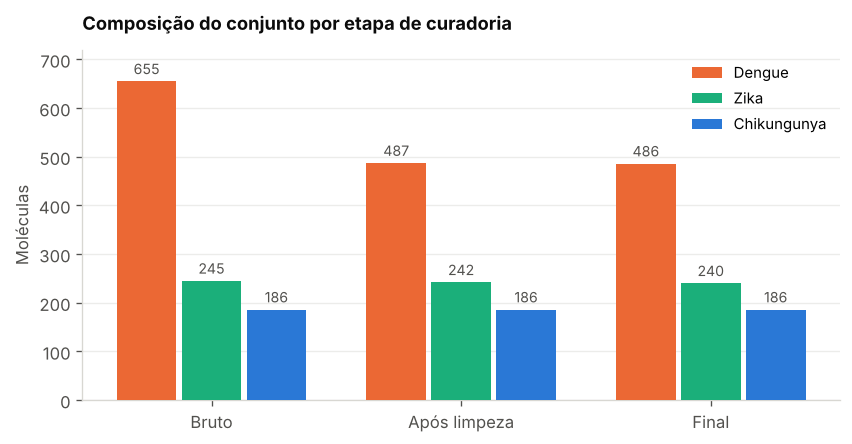

In [7]:
# ---- Figura 1: composicao do conjunto ----
etapas = ["Bruto", "Após limpeza", "Final"]
classes = ["dengue", "zika", "chikungunya"]
x = np.arange(len(etapas)); larg = 0.26

fig, ax = plt.subplots(figsize=(7.2, 3.8))
for i, c in enumerate(classes):
    vals = [tab1.loc[c, e] for e in etapas]
    pos = x + (i - 1) * larg
    ax.bar(pos, vals, larg * 0.92, color=COR_CLASSE[c], label=c.capitalize(), zorder=3)
    for p, v in zip(pos, vals):
        ax.text(p, v + 8, str(v), ha="center", va="bottom", fontsize=8.5, color=TINTA2)

ax.set_title("Composição do conjunto por etapa de curadoria")
ax.set_ylabel("Moléculas")
ax.set_xticks(x); ax.set_xticklabels(etapas)
ax.set_ylim(0, 720)
ax.yaxis.grid(True, zorder=0); ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper right", fontsize=9)
plt.tight_layout(); plt.show()

massa molecular: 157.2 a 746.6 Da
fora da faixa 200-700 Da aceita pela plataforma: 23 moleculas (2.5%)


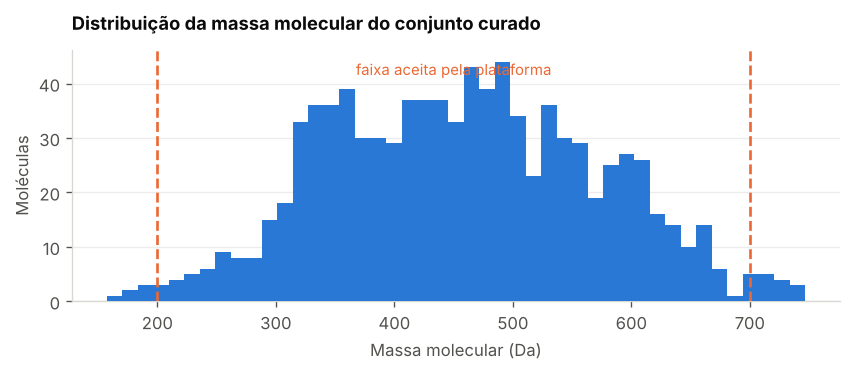

In [8]:
# ---- distribuicao de massa: justifica a faixa aceita pela plataforma ----
massa = df_desc["MolWt"]
fora = ((massa < 200) | (massa > 700)).sum()
print(f"massa molecular: {massa.min():.1f} a {massa.max():.1f} Da")
print(f"fora da faixa 200-700 Da aceita pela plataforma: {fora} moleculas ({100*fora/len(massa):.1f}%)")

fig, ax = plt.subplots(figsize=(7.2, 3.2))
ax.hist(massa, bins=45, color=AZUL, zorder=3)
for lim in (200, 700):
    ax.axvline(lim, color=LARANJA, lw=1.6, ls="--", zorder=4)
ax.text(450, ax.get_ylim()[1]*0.9, "faixa aceita pela plataforma",
        ha="center", fontsize=9, color=LARANJA)
ax.set_title("Distribuição da massa molecular do conjunto curado")
ax.set_xlabel("Massa molecular (Da)"); ax.set_ylabel("Moléculas")
ax.yaxis.grid(True, zorder=0); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

---
## 4. O pipeline, e por que ele importa

As quatro etapas vão dentro de uma `Pipeline` do `imbalanced-learn`:

| Etapa | O que faz |
|---|---|
| `RandomUnderSampler` | iguala as classes subamostrando as maiores — **só no treino** |
| `RobustScaler` | escala por mediana e intervalo interquartil, resistente a valores extremos |
| `SelectKBest(f_classif)` | mantém os 20 descritores mais discriminantes |
| `ExtraTreesClassifier` | o classificador |

O ponto decisivo: dentro da `Pipeline`, essas etapas são reajustadas do zero a cada
partição de treino durante a validação cruzada. Nenhuma informação da partição de
avaliação participa do ajuste.

A célula seguinte mede o tamanho do erro que isso evita.

In [9]:
def criar_pipeline(modelo=None, seed=RANDOM_STATE):
    return Pipeline([
        ("rus",      RandomUnderSampler(random_state=seed)),
        ("scaler",   RobustScaler()),
        ("selector", SelectKBest(f_classif, k=N_FEATURES)),
        ("model",    modelo if modelo is not None else
                     ExtraTreesClassifier(n_estimators=N_ESTIMATORS,
                                          random_state=seed, n_jobs=-1)),
    ])

criar_pipeline()

,steps,"[('rus', ...), ('scaler', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,sampling_strategy,'auto'
,random_state,42
,replacement,False
,with_centering,True
,with_scaling,True
,quantile_range,"(25.0, ...)"
,copy,True


In [10]:
# ---- demonstracao do vazamento ----
Xtr, Xte, ytr, yte = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)
print(f"treino: {len(ytr)}   teste: {len(yte)}")

# (A) CORRETO: tudo ajustado dentro do treino
p_ok = criar_pipeline(); p_ok.fit(Xtr, ytr)
acc_ok = accuracy_score(yte, p_ok.predict(Xte))
f1_ok  = f1_score(yte, p_ok.predict(Xte), average="macro")

# (B) COM VAZAMENTO: scaler e selector ajustados no conjunto inteiro
Xs = pd.DataFrame(RobustScaler().fit_transform(X), columns=X.columns)
sel_vaz = SelectKBest(f_classif, k=N_FEATURES).fit(Xs, y)       # <-- ve os rotulos do teste
Xsel = pd.DataFrame(sel_vaz.transform(Xs), columns=X.columns[sel_vaz.get_support()])
Xtr_v, Xte_v, ytr_v, yte_v = train_test_split(
    Xsel, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)
m_vaz = ExtraTreesClassifier(n_estimators=N_ESTIMATORS, random_state=RANDOM_STATE, n_jobs=-1)
m_vaz.fit(Xtr_v, ytr_v)
acc_vaz = accuracy_score(yte_v, m_vaz.predict(Xte_v))
f1_vaz  = f1_score(yte_v, m_vaz.predict(Xte_v), average="macro")

print(f"\n(A) pipeline correta     acc {acc_ok:.3f}   macro-F1 {f1_ok:.3f}")
print(f"(B) com vazamento        acc {acc_vaz:.3f}   macro-F1 {f1_vaz:.3f}")
print(f"\ninflacao artificial:     {acc_vaz-acc_ok:+.3f} de acuracia, {f1_vaz-f1_ok:+.3f} de macro-F1")

dif = sorted(set(Xsel.columns) - set(X.columns[p_ok.named_steps['selector'].get_support()]))
print(f"\ndescritores que so o modelo com vazamento escolheu: {dif}")

treino: 729   teste: 183



(A) pipeline correta     acc 0.721   macro-F1 0.707
(B) com vazamento        acc 0.776   macro-F1 0.755

inflacao artificial:     +0.055 de acuracia, +0.048 de macro-F1

descritores que so o modelo com vazamento escolheu: ['NumHeteroatoms', 'NumRotatableBonds', 'PEOE_VSA1', 'PEOE_VSA9', 'SlogP_VSA8', 'fr_piperzine', 'fr_urea']


---
## 5. Benchmark dos treze algoritmos

Validação cruzada estratificada de 5 partições, repetida 5 vezes: **25 ajustes por
algoritmo**. Com n = 912 e três classes desbalanceadas, uma única divisão 80/20 deixa
apenas 183 moléculas no teste e produz estimativas instáveis; a repetição permite relatar
o desvio-padrão.

O critério principal é o **macro-F1**, que pesa as três classes igualmente,
independentemente do tamanho de cada uma.

In [11]:
MODELOS = {
    "Extra Trees":         ExtraTreesClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "Random Forest":       RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting":   GradientBoostingClassifier(random_state=RANDOM_STATE),
    "AdaBoost":            AdaBoostClassifier(random_state=RANDOM_STATE),
    "Decision Tree":       DecisionTreeClassifier(random_state=RANDOM_STATE),
    "SVM (RBF)":           SVC(random_state=RANDOM_STATE),
    "Linear SVM":          LinearSVC(random_state=RANDOM_STATE, max_iter=5000),
    "k-Nearest Neighbors": KNeighborsClassifier(),
    "Logistic Regression": LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),
    "Ridge Classifier":    RidgeClassifier(random_state=RANDOM_STATE),
    "Gaussian NB":         GaussianNB(),
    "Bernoulli NB":        BernoulliNB(),
    "LDA":                 LinearDiscriminantAnalysis(),
}

cv = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=RANDOM_STATE)
particoes = list(cv.split(X, y))
print(f"{len(particoes)} particoes por algoritmo, {len(MODELOS)} algoritmos")

linhas = []
for nome, mdl in MODELOS.items():
    accs, f1s = [], []
    for tr, te in particoes:
        p = criar_pipeline(clone(mdl))
        p.fit(X.iloc[tr], y[tr])
        pred = p.predict(X.iloc[te])
        accs.append(accuracy_score(y[te], pred))
        f1s.append(f1_score(y[te], pred, average="macro"))
    linhas.append({"Algoritmo": nome, "Acurácia": np.mean(accs), "±acc": np.std(accs),
                   "Macro-F1": np.mean(f1s), "±f1": np.std(f1s)})
    print(f"  {nome:22s} acc {np.mean(accs):.3f}±{np.std(accs):.3f}   F1 {np.mean(f1s):.3f}±{np.std(f1s):.3f}")

tab2 = pd.DataFrame(linhas).sort_values("Macro-F1", ascending=False).reset_index(drop=True)
base = np.bincount(y).max() / len(y)
print(f"\nlinha de base (classe majoritaria): {base:.3f}")

25 particoes por algoritmo, 13 algoritmos


  Extra Trees            acc 0.728±0.027   F1 0.718±0.026


  Random Forest          acc 0.706±0.038   F1 0.696±0.037


  Gradient Boosting      acc 0.683±0.039   F1 0.671±0.038


  AdaBoost               acc 0.572±0.035   F1 0.554±0.034


  Decision Tree          acc 0.617±0.041   F1 0.597±0.044


  SVM (RBF)              acc 0.595±0.034   F1 0.586±0.032


  Linear SVM             acc 0.551±0.031   F1 0.536±0.031


  k-Nearest Neighbors    acc 0.601±0.039   F1 0.591±0.036


  Logistic Regression    acc 0.554±0.032   F1 0.538±0.034


  Ridge Classifier       acc 0.557±0.029   F1 0.541±0.031


  Gaussian NB            acc 0.477±0.080   F1 0.450±0.091


  Bernoulli NB           acc 0.531±0.040   F1 0.515±0.040


  LDA                    acc 0.554±0.033   F1 0.539±0.034

linha de base (classe majoritaria): 0.533


In [12]:
display(tab2.style.format({"Acurácia": "{:.3f}", "±acc": "{:.3f}",
                           "Macro-F1": "{:.3f}", "±f1": "{:.3f}"}).hide(axis="index"))

Algoritmo,Acurácia,±acc,Macro-F1,±f1
Extra Trees,0.728,0.027,0.718,0.026
Random Forest,0.706,0.038,0.696,0.037
Gradient Boosting,0.683,0.039,0.671,0.038
Decision Tree,0.617,0.041,0.597,0.044
k-Nearest Neighbors,0.601,0.039,0.591,0.036
SVM (RBF),0.595,0.034,0.586,0.032
AdaBoost,0.572,0.035,0.554,0.034
Ridge Classifier,0.557,0.029,0.541,0.031
LDA,0.554,0.033,0.539,0.034
Logistic Regression,0.554,0.032,0.538,0.034


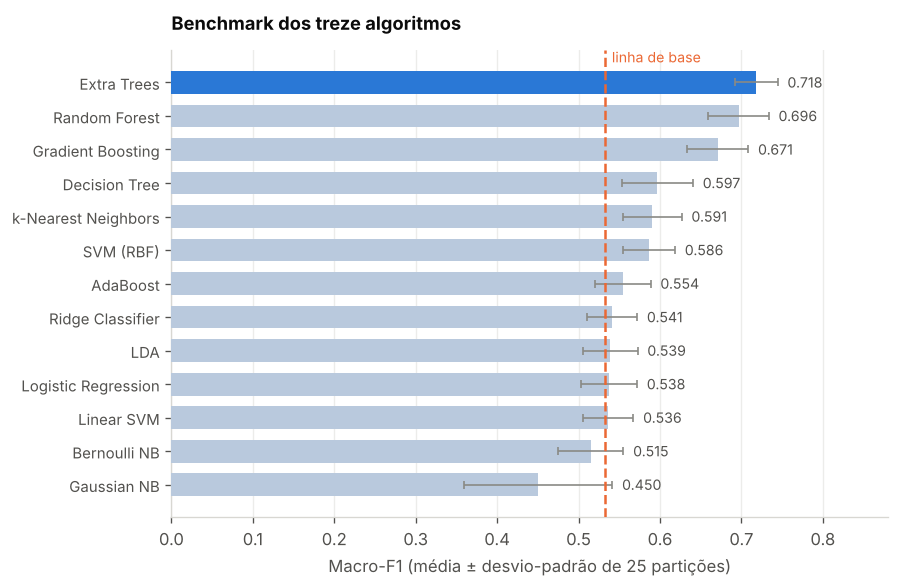

In [13]:
# ---- Figura 2: benchmark ----
d = tab2.iloc[::-1]
fig, ax = plt.subplots(figsize=(7.6, 5.0))
pos = np.arange(len(d))
cores = [AZUL if a == "Extra Trees" else "#b9c9dd" for a in d["Algoritmo"]]
ax.barh(pos, d["Macro-F1"], 0.68, xerr=d["±f1"], color=cores, zorder=3,
        error_kw=dict(ecolor="#8a8a85", lw=1, capsize=2.5))
for p, v, s in zip(pos, d["Macro-F1"], d["±f1"]):
    ax.text(v + s + 0.012, p, f"{v:.3f}", va="center", fontsize=8.5, color=TINTA2)
ax.axvline(base, color=LARANJA, lw=1.5, ls="--", zorder=4)
ax.text(base + 0.008, len(d) - 0.4, "linha de base", fontsize=8.5, color=LARANJA)
ax.set_yticks(pos); ax.set_yticklabels(d["Algoritmo"], fontsize=9)
ax.set_xlabel("Macro-F1 (média ± desvio-padrão de 25 partições)")
ax.set_title("Benchmark dos treze algoritmos")
ax.set_xlim(0, 0.88)
ax.xaxis.grid(True, zorder=0); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

---
## 6. Modelo escolhido: Extra Trees

### 6.1 Partição de teste retida

In [14]:
pipe = criar_pipeline()
pipe.fit(Xtr, ytr)
ypred = pipe.predict(Xte)

print(classification_report(yte, ypred, target_names=le.classes_, digits=3))
print("balanced accuracy:", round(balanced_accuracy_score(yte, ypred), 3))

              precision    recall  f1-score   support

 chikungunya      0.604     0.865     0.711        37
      dengue      0.895     0.694     0.782        98
        zika      0.593     0.667     0.627        48

    accuracy                          0.721       183
   macro avg      0.697     0.742     0.707       183
weighted avg      0.757     0.721     0.727       183

balanced accuracy: 0.742


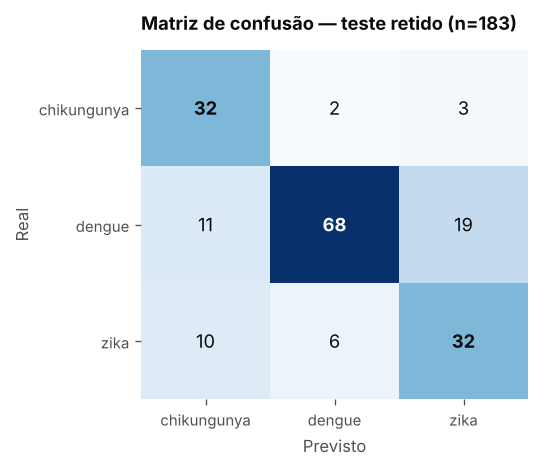

In [15]:
def heatmap_confusao(cm, titulo, ax):
    ax.imshow(cm, cmap="Blues", aspect="auto")
    n = len(le.classes_)
    lim = cm.max()
    for i in range(n):
        for j in range(n):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=11,
                    color="white" if cm[i, j] > lim * 0.55 else TINTA,
                    fontweight="bold" if i == j else "normal")
    ax.set_xticks(range(n)); ax.set_xticklabels(le.classes_, fontsize=9)
    ax.set_yticks(range(n)); ax.set_yticklabels(le.classes_, fontsize=9)
    ax.set_xlabel("Previsto"); ax.set_ylabel("Real")
    ax.set_title(titulo)
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)

fig, ax = plt.subplots(figsize=(4.6, 4.0))
heatmap_confusao(confusion_matrix(yte, ypred), "Matriz de confusão — teste retido (n=183)", ax)
plt.tight_layout(); plt.show()

### 6.2 Validação cruzada sobre o conjunto completo

Aqui **toda** molécula recebe uma predição fora da amostra, o que dá uma matriz de
confusão sobre as 912 e não sobre 183.

In [16]:
votos = np.zeros((len(y), len(le.classes_)), dtype=int)
accs, f1s = [], []
for tr, te in particoes:
    p = criar_pipeline(); p.fit(X.iloc[tr], y[tr])
    pr = p.predict(X.iloc[te])
    accs.append(accuracy_score(y[te], pr)); f1s.append(f1_score(y[te], pr, average="macro"))
    for i, idx in enumerate(te):
        votos[idx, pr[i]] += 1

y_oof = votos.argmax(axis=1)
print(classification_report(y, y_oof, target_names=le.classes_, digits=3))
print(f"média das 25 partições: acc {np.mean(accs):.3f}±{np.std(accs):.3f}  "
      f"macro-F1 {np.mean(f1s):.3f}±{np.std(f1s):.3f}")

              precision    recall  f1-score   support

 chikungunya      0.623     0.844     0.717       186
      dengue      0.895     0.716     0.795       486
        zika      0.683     0.771     0.724       240

    accuracy                          0.757       912
   macro avg      0.733     0.777     0.745       912
weighted avg      0.783     0.757     0.761       912

média das 25 partições: acc 0.728±0.027  macro-F1 0.718±0.026


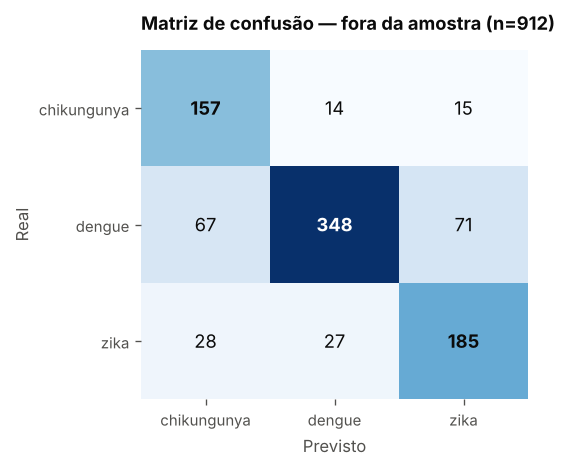

In [17]:
fig, ax = plt.subplots(figsize=(4.6, 4.0))
heatmap_confusao(confusion_matrix(y, y_oof), "Matriz de confusão — fora da amostra (n=912)", ax)
plt.tight_layout(); plt.show()

---
## 7. Estabilidade

Duas perguntas que um parecerista faz: o resultado depende da semente? E os descritores
escolhidos são sempre os mesmos?

In [18]:
# ---- sensibilidade a semente do classificador ----
a, f = [], []
for s in range(30):
    q = criar_pipeline(seed=s); q.fit(Xtr, ytr); z = q.predict(Xte)
    a.append(accuracy_score(yte, z)); f.append(f1_score(yte, z, average="macro"))
print(f"30 sementes -> acuracia {np.mean(a):.3f}±{np.std(a):.3f}  [{min(a):.3f} a {max(a):.3f}]")
print(f"            -> macro-F1 {np.mean(f):.3f}±{np.std(f):.3f}  [{min(f):.3f} a {max(f):.3f}]")

30 sementes -> acuracia 0.732±0.030  [0.689 a 0.798]
            -> macro-F1 0.719±0.029  [0.674 a 0.791]


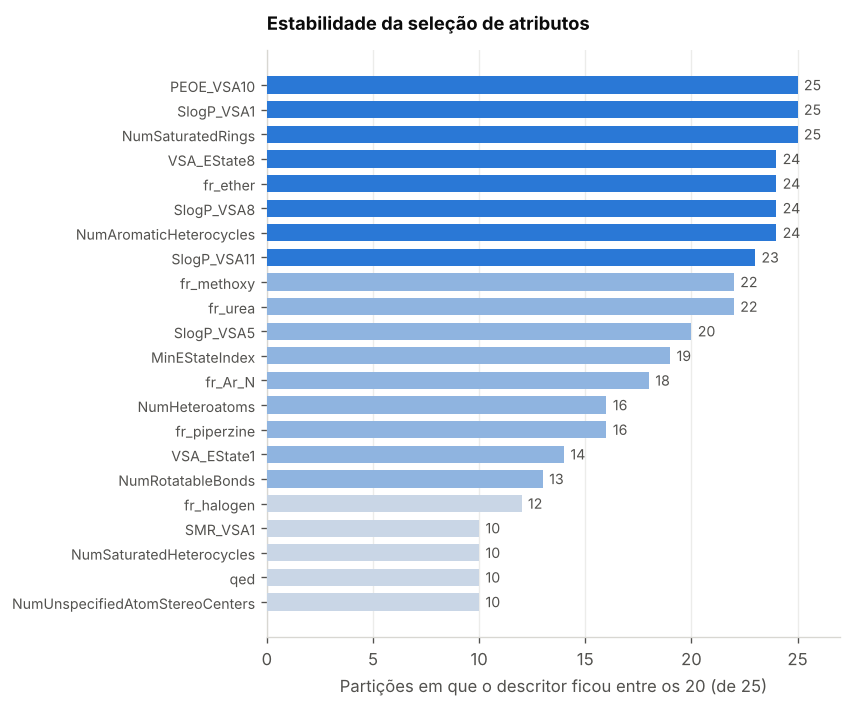

selecionados em pelo menos 23 das 25 particoes (8): ['NumAromaticHeterocycles', 'NumSaturatedRings', 'PEOE_VSA10', 'SlogP_VSA1', 'SlogP_VSA11', 'SlogP_VSA8', 'VSA_EState8', 'fr_ether']


In [19]:
# ---- frequencia de selecao de cada descritor nas 25 particoes ----
freq = Counter()
for tr, te in particoes:
    q = criar_pipeline(); q.fit(X.iloc[tr], y[tr])
    freq.update(X.columns[q.named_steps["selector"].get_support()].tolist())

top = freq.most_common(22)
nomes = [k for k, _ in top][::-1]
vals  = [v for _, v in top][::-1]

fig, ax = plt.subplots(figsize=(7.2, 6.0))
cores = [AZUL if v >= 23 else ("#8fb4e0" if v >= 13 else "#c9d6e6") for v in vals]
ax.barh(np.arange(len(nomes)), vals, 0.7, color=cores, zorder=3)
for i, v in enumerate(vals):
    ax.text(v + 0.3, i, f"{v}", va="center", fontsize=8.5, color=TINTA2)
ax.set_yticks(np.arange(len(nomes))); ax.set_yticklabels(nomes, fontsize=8.5)
ax.set_xlabel("Partições em que o descritor ficou entre os 20 (de 25)")
ax.set_title("Estabilidade da seleção de atributos")
ax.set_xlim(0, 27); ax.xaxis.set_major_locator(MultipleLocator(5))
ax.xaxis.grid(True, zorder=0); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

estaveis = [k for k, v in freq.items() if v >= 23]
print(f"selecionados em pelo menos 23 das 25 particoes ({len(estaveis)}): {sorted(estaveis)}")

---
## 8. Modelo final e artefatos

O modelo entregue à plataforma é reajustado sobre **todas** as 912 moléculas: as métricas
acima estimam o desempenho da arquitetura, e o modelo implantado aproveita o conjunto
inteiro.

In [20]:
modelo_final = criar_pipeline()
modelo_final.fit(X, y)

selecionados = X.columns[modelo_final.named_steps["selector"].get_support()]
importancias = (pd.Series(modelo_final.named_steps["model"].feature_importances_,
                          index=selecionados)
                  .sort_values(ascending=False))

tab5 = pd.DataFrame({
    "Descritor": importancias.index,
    "Importância": importancias.values,
    "Freq. seleção": [f"{freq[d]}/25" for d in importancias.index],
})
tab5.index = np.arange(1, len(tab5) + 1)
display(tab5.style.format({"Importância": "{:.4f}"}))

,Descritor,Importância,Freq. seleção
1,SlogP_VSA1,0.0734,25/25
2,MinEStateIndex,0.0712,19/25
3,SlogP_VSA8,0.0629,24/25
4,VSA_EState8,0.0607,24/25
5,PEOE_VSA10,0.0585,25/25
6,SlogP_VSA5,0.0562,20/25
7,NumRotatableBonds,0.0559,13/25
8,fr_Ar_N,0.0558,18/25
9,SMR_VSA1,0.0526,10/25
10,NumHeteroatoms,0.0523,16/25


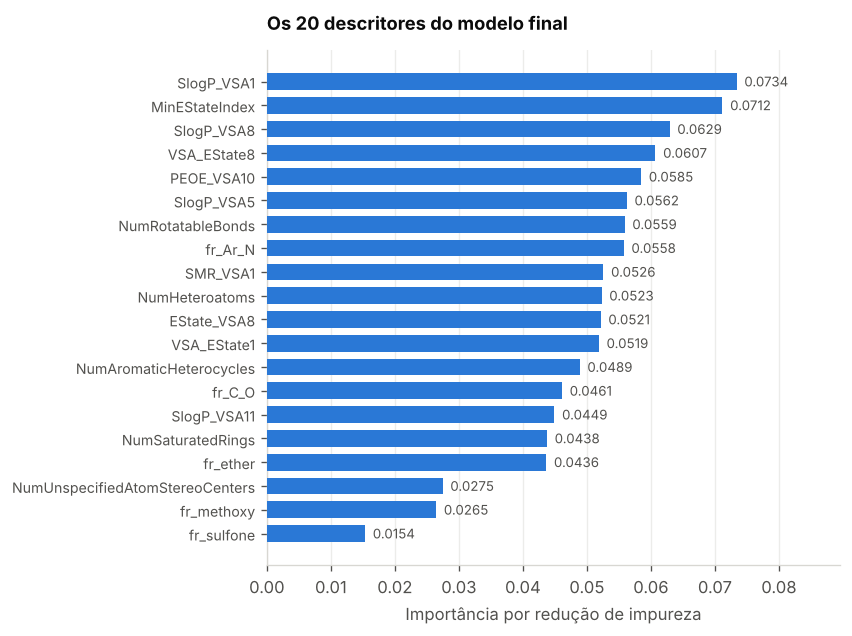

In [21]:
fig, ax = plt.subplots(figsize=(7.2, 5.4))
d = importancias.iloc[::-1]
ax.barh(np.arange(len(d)), d.values, 0.7, color=AZUL, zorder=3)
for i, v in enumerate(d.values):
    ax.text(v + 0.0012, i, f"{v:.4f}", va="center", fontsize=8, color=TINTA2)
ax.set_yticks(np.arange(len(d))); ax.set_yticklabels(d.index, fontsize=8.5)
ax.set_xlabel("Importância por redução de impureza")
ax.set_title("Os 20 descritores do modelo final")
ax.set_xlim(0, max(d.values) * 1.22)
ax.xaxis.grid(True, zorder=0); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

### 8.1 Explicabilidade (SHAP)

O mesmo cálculo que a plataforma faz a cada predição, aqui agregado sobre o conjunto todo
para mostrar quais descritores mais pesam globalmente, por classe.

formato dos valores SHAP: (912, 20, 3)


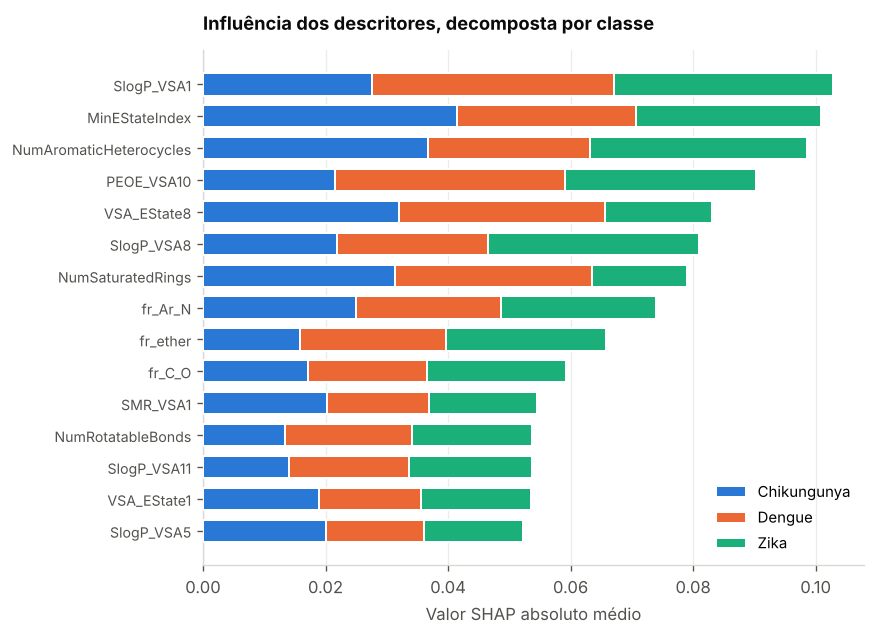

In [22]:
import shap

scaler_f   = modelo_final.named_steps["scaler"]
selector_f = modelo_final.named_steps["selector"]
modelo_f   = modelo_final.named_steps["model"]

X_sel = pd.DataFrame(selector_f.transform(scaler_f.transform(X)), columns=selecionados)
explainer = shap.TreeExplainer(modelo_f)
sv = np.asarray(explainer.shap_values(X_sel))      # (n_amostras, n_atributos, n_classes)
print("formato dos valores SHAP:", sv.shape)

med = pd.DataFrame({cls: np.abs(sv[:, :, i]).mean(axis=0)
                    for i, cls in enumerate(le.classes_)}, index=selecionados)
med["total"] = med.sum(axis=1)
med = med.sort_values("total", ascending=False).head(15).drop(columns="total")

fig, ax = plt.subplots(figsize=(7.4, 5.4))
d = med.iloc[::-1]
esq = np.zeros(len(d))
for cls in le.classes_:
    ax.barh(np.arange(len(d)), d[cls], 0.7, left=esq, color=COR_CLASSE[cls],
            label=cls.capitalize(), zorder=3, edgecolor="white", linewidth=1.2)
    esq += d[cls].values
ax.set_yticks(np.arange(len(d))); ax.set_yticklabels(d.index, fontsize=8.5)
ax.set_xlabel("Valor SHAP absoluto médio")
ax.set_title("Influência dos descritores, decomposta por classe")
ax.legend(frameon=False, fontsize=9, loc="lower right")
ax.xaxis.grid(True, zorder=0); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

### 8.2 Gravar os artefatos

In [23]:
artefatos = [(modelo_final, "modelo_final.pkl"),
             (le,           "label_encoder.pkl"),
             (X.columns.tolist(), "colunas.pkl")]

for obj, nome in artefatos:
    caminho = os.path.join(OUT_DIR, nome)
    joblib.dump(obj, caminho)
    h = hashlib.sha256(open(caminho, "rb").read()).hexdigest()
    print(f"{nome:20s} {os.path.getsize(caminho):>10,} bytes   sha256 {h[:24]}...")

modelo_final.pkl      9,003,702 bytes   sha256 811a627cbaaabbc5354ba7e4...
label_encoder.pkl           503 bytes   sha256 3010561a562e2a624aa172ad...
colunas.pkl               3,050 bytes   sha256 99387dc42536b67dbc5d8515...


### 8.3 Verificação de reprodutibilidade

O modelo antigo usava `ExtraTreesClassifier()` sem semente, e cada execução produzia um
modelo diferente. A célula abaixo treina duas vezes e compara.

In [24]:
m1 = criar_pipeline(); m1.fit(X, y)
m2 = criar_pipeline(); m2.fit(X, y)

t1 = m1.named_steps["model"].estimators_
t2 = m2.named_steps["model"].estimators_
arvores_iguais = all(np.array_equal(a.tree_.threshold, b.tree_.threshold) and
                     np.array_equal(a.tree_.feature,   b.tree_.feature)
                     for a, b in zip(t1, t2))
selecao_igual = np.array_equal(m1.named_steps["selector"].get_support(),
                               m2.named_steps["selector"].get_support())
predicoes_iguais = np.array_equal(m1.predict(X), m2.predict(X))

print(f"mesmas {len(t1)} arvores:        {arvores_iguais}")
print(f"mesma selecao de atributos:  {selecao_igual}")
print(f"mesmas predicoes:            {predicoes_iguais}")
print("\nREPRODUTIVEL" if all([arvores_iguais, selecao_igual, predicoes_iguais])
      else "\nNAO REPRODUTIVEL")

mesmas 200 arvores:        True
mesma selecao de atributos:  True
mesmas predicoes:            True

REPRODUTIVEL


### 8.4 Teste de ponta a ponta

Confere que os artefatos recém-gravados funcionam no mesmo caminho de inferência que a
plataforma usa.

In [25]:
pipe_carregado = joblib.load(os.path.join(OUT_DIR, "modelo_final.pkl"))
le_carregado   = joblib.load(os.path.join(OUT_DIR, "label_encoder.pkl"))
cols_carregado = joblib.load(os.path.join(OUT_DIR, "colunas.pkl"))

exemplos = [
    "COc1ccc2nc(S(N)(=O)=O)sc2c1",                      # fora do conjunto de treino
    "CC(=O)Nc1ccc(O)cc1",                               # paracetamol (massa fora da faixa)
    "Cc1ccc2c(c1)nc(n2C)S(=O)Cc1ncc(C)c(OC)c1C",        # fora do conjunto de treino
]

for smi in exemplos:
    mol = Chem.MolFromSmiles(smi)
    massa = Descriptors.MolWt(mol)
    if not (200 <= massa <= 700):
        print(f"{smi[:46]:46s}  REJEITADO: massa {massa:.1f} Da fora de 200-700")
        continue
    linha = calcular_descritores(pd.DataFrame({"Smiles": [smi]})).reindex(
        columns=cols_carregado, fill_value=0)
    prob = pipe_carregado.predict_proba(linha)[0]
    cls  = le_carregado.inverse_transform(pipe_carregado.predict(linha))[0]
    detalhe = "  ".join(f"{c} {p:.2f}" for c, p in zip(le_carregado.classes_, prob))
    print(f"{smi[:46]:46s}  {massa:6.1f} Da  ->  {cls:12s}  ({detalhe})")

COc1ccc2nc(S(N)(=O)=O)sc2c1                      244.3 Da  ->  zika          (chikungunya 0.14  dengue 0.33  zika 0.53)
CC(=O)Nc1ccc(O)cc1                              REJEITADO: massa 151.2 Da fora de 200-700
Cc1ccc2c(c1)nc(n2C)S(=O)Cc1ncc(C)c(OC)c1C        343.5 Da  ->  zika          (chikungunya 0.22  dengue 0.30  zika 0.47)


---
## Resumo

| | Valor |
|---|---|
| Moléculas | 912 (486 dengue, 240 zika, 186 chikungunya) |
| Descritores calculados | 217 |
| Descritores usados pelo modelo | 20 |
| Modelo | Extra Trees, 200 árvores, `random_state=42` |
| **Acurácia (VC 5×5)** | **0,728 ± 0,027** |
| **Macro-F1 (VC 5×5)** | **0,718 ± 0,026** |
| Linha de base (classe majoritária) | 0,533 |

### O que ainda falta para a publicação

1. **Procedência dos rótulos.** Documentar a base de origem de cada coleção, o tipo de
   ensaio biológico e o critério usado para considerar um composto "associado" a cada
   vírus. Sem isso a seção de Métodos não é avaliável.
2. **Ausência de classe "inativo".** O modelo responde qual dos três vírus é o mais
   provável, nunca "nenhum". Qualquer molécula submetida sai classificada com confiança.
   O título e o resumo precisam refletir isso.
3. **Validação externa.** Um conjunto independente, de outra fonte, antes de usar o modelo
   para priorizar experimentos.
4. **Domínio de aplicabilidade.** A faixa de massa é um filtro grosseiro; falta uma
   análise formal que sinalize moléculas fora do espaço químico do treino.